In [1]:
from math import log, sqrt, pi
import numpy as np
import matplotlib.pyplot as plt

seed = 42     #	Random Number Generator

In [2]:
def myRandom():
  global seed
  a = 1664525
  c = 1013904223
  m = 2**32
  seed = (a * seed + c) % m
  return seed / m

def myUniform(a, b):
  return a + (b - a) * myRandom()

In [3]:
#	Marsaglia Polar Method (Generate n Gaussian samples using Marsaglia polar method)
def gaussian(mu, sigma, n=1):
  g = []
  while len(g) < n:
    u1 = myUniform(-1, 1)
    u2 = myUniform(-1, 1)
    s = u1*u1 + u2*u2
    if 0 < s < 1:
      k = sqrt(-2 * log(s) / s)
      x = u1 * k
      y = u2 * k
      g.append(mu + sigma * x)
      if len(g) < n:
        g.append(mu + sigma * y)
  return g if n > 1 else g[0]

In [4]:
def generate_gaussian(mean, covariance):   #Generate one 2-D point from a Gaussian
# Uses Cholesky-style transform + Marsaglia polar
  a = covariance[0][0]
  b = covariance[0][1]
  c = covariance[1][1]
  z1 = gaussian(0, 1)
  z2 = gaussian(0, 1)
  x1 = mean[0] + sqrt(a) * z1
  x2 = mean[1] + (b / sqrt(a)) * z1 + sqrt(c - (b*b)/a) * z2
  return [x1, x2]


In [5]:
#	Parameters
N = 5000
K = 3

weights1 = [0.40, 0.35, 0.25]
means1 = [[4, -2], [0, 3], [7, -3]]
weights2 = [0.30, 0.40, 0.30]
means2 = [[-3, 3], [1, -3], [5, 3]]

covariance_types = { "Spherical": [
[[1, 0], [0, 1]],
[[1, 0], [0, 1]],
[[1, 0], [0, 1]]
],
"Diagonal": [
[[2, 0], [0, 0.5]],
[[0.5, 0], [0, 2]],
[[1.5, 0], [0, 0.7]]
],
"Full": [
[[2, 0.8], [0.8, 1]],
[[1.5, -0.6], [-0.6, 1]],
[[1, 0.5], [0.5, 1.5]]
]
}

In [6]:
#	Generate data
def generate_data(N, weights, means, covariances):
  data = []
  component_labels = []
  for _ in range(N):
    u = myRandom()
    if u < weights[0]:
      component = 0
    elif u < weights[0] + weights[1]:
      component = 1
    else:
      component = 2
    point = generate_gaussian(means[component], covariances[component])
    data.append(point)
    component_labels.append(component)
  return data, component_labels

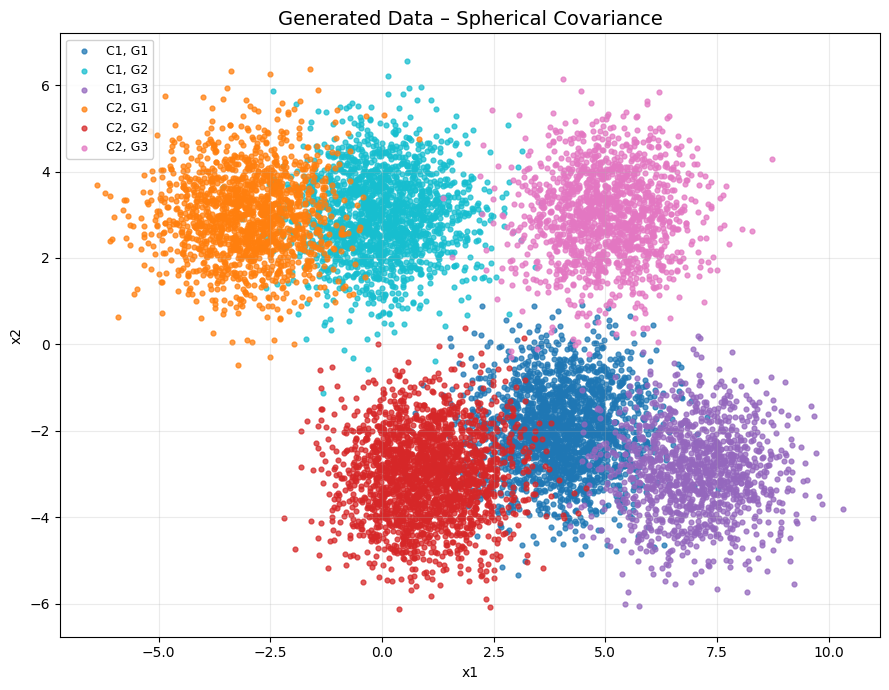

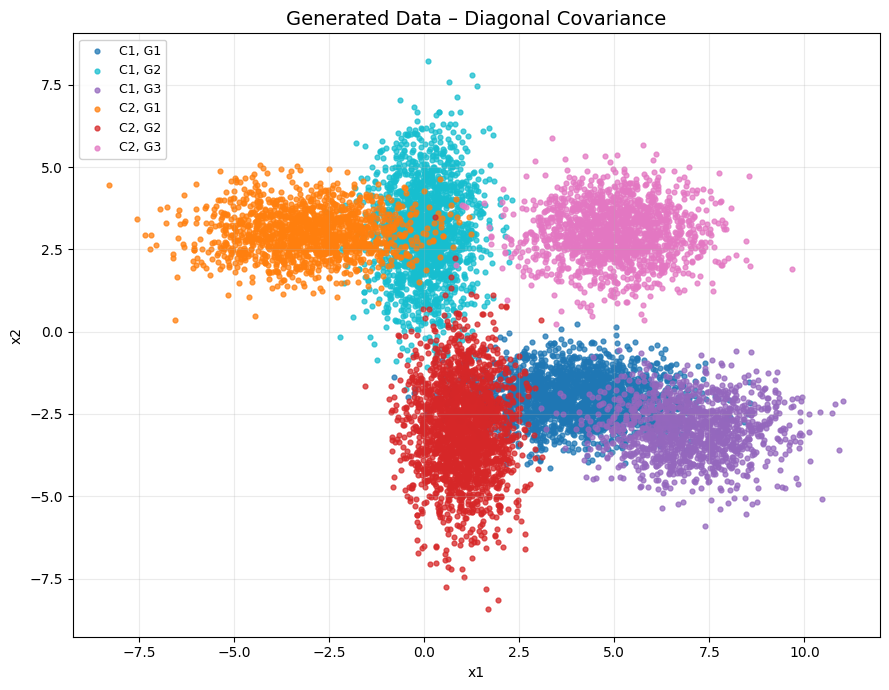

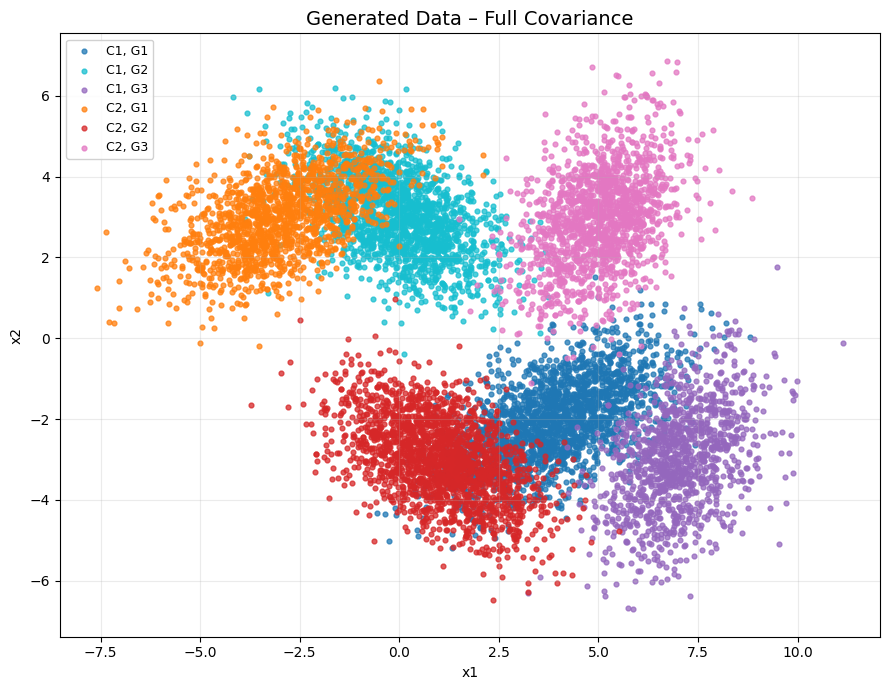

In [7]:
#	Generate & plot
generated_data = {}

colors = {
(1, 0): "#1f77b4",
(1, 1): "#17becf",
(1, 2): "#9467bd",
(2, 0): "#ff7f0e",
(2, 1): "#d62728",
(2, 2): "#e377c2",
}

for name, covariances in covariance_types.items():
  class1, labels1 = generate_data(N, weights1, means1, covariances)
  class2, labels2 = generate_data(N, weights2, means2, covariances)

  generated_data[name] = { "Class 1": class1,
  "Class 2": class2,
  "Labels 1": labels1,
  "Labels 2": labels2
  }
  class1_np = np.array(class1)
  class2_np = np.array(class2)

  plt.figure(figsize=(9, 7))
  for comp in range(3):
    mask = np.array(labels1) == comp
    plt.scatter(class1_np[mask, 0], class1_np[mask, 1], c=colors[(1, comp)], s=12, alpha=0.75, label=f"C1, G{comp+1}")
  for comp in range(3):
    mask = np.array(labels2) == comp
    plt.scatter(class2_np[mask, 0], class2_np[mask, 1], c=colors[(2, comp)], s=12, alpha=0.75, label=f"C2, G{comp+1}")
  plt.title(f"Generated Data – {name} Covariance", fontsize=14)
  plt.xlabel("x1")
  plt.ylabel("x2")
  plt.legend(loc="upper left", fontsize=9, framealpha=0.9)
  plt.grid(True, alpha=0.25)
  plt.tight_layout()
  plt.show()

In [8]:
#	80-20 Split
def train_test_split(data, ratio=0.8):
  data = list(data)
  for i in range(len(data)-1, 0, -1):
    j = int(myRandom() * (i+1))
    data[i], data[j] = data[j], data[i]
  n = int(len(data) * ratio)
  return data[:n], data[n:]

datasets = {}
for name in covariance_types:
  train1, test1 = train_test_split(generated_data[name]["Class 1"])
  train2, test2 = train_test_split(generated_data[name]["Class 2"])
  datasets[name] = {"train1": train1, "test1": test1, "train2": train2, "test2": test2}
  print(f"{name}: Class1 train={len(train1)} test={len(test1)} | "f"Class2 train={len(train2)} test={len(test2)}")


Spherical: Class1 train=4000 test=1000 | Class2 train=4000 test=1000
Diagonal: Class1 train=4000 test=1000 | Class2 train=4000 test=1000
Full: Class1 train=4000 test=1000 | Class2 train=4000 test=1000


In [9]:
#	K-Means
def dist2(p, q):
  return (p[0]-q[0])**2 + (p[1]-q[1])**2

def kmeans(data, k=3, max_iter=100):
  data = [list(p) for p in data]
  centroids = [list(data[int(myRandom()*len(data))])]
  while len(centroids) < k:
    d = [min(dist2(p, c) for c in centroids) for p in data]
    centroids.append(list(data[d.index(max(d))]))
  for _ in range(max_iter):
    clusters = [[] for _ in range(k)]
    for p in data:
      clusters[min(range(k), key=lambda i: dist2(p, centroids[i]))].append(p)
    new_centroids = []
    for i in range(k):
      if not clusters[i]:
        new_centroids.append(centroids[i])
      else:
        mx = sum(p[0] for p in clusters[i]) / len(clusters[i])
        my = sum(p[1] for p in clusters[i]) / len(clusters[i])
        new_centroids.append([mx, my])
    if max(dist2(centroids[i], new_centroids[i]) for i in range(k)) < 1e-8:
      break
    centroids = new_centroids
  return centroids

kmeans_models = {}
for name in covariance_types:
  c1 = kmeans(datasets[name]["train1"])
  c2 = kmeans(datasets[name]["train2"])
  kmeans_models[name] = {"Class 1": c1, "Class 2": c2}
  print(f"\n{name}")
  print("Class 1 centroids:", [[round(v,3) for v in c] for c in c1])
  print("Class 2 centroids:", [[round(v,3) for v in c] for c in c2])


Spherical
Class 1 centroids: [[3.932, -1.976], [0.035, 3.003], [7.0, -2.947]]
Class 2 centroids: [[-2.998, 2.963], [5.029, 2.974], [0.999, -3.041]]

Diagonal
Class 1 centroids: [[6.963, -2.821], [0.008, 3.085], [3.627, -1.993]]
Class 2 centroids: [[4.991, 3.004], [1.006, -3.013], [-3.035, 3.005]]

Full
Class 1 centroids: [[3.491, -2.178], [-0.047, 3.065], [6.811, -2.592]]
Class 2 centroids: [[5.013, 2.967], [-3.031, 2.982], [1.029, -3.005]]


In [10]:
#	Classification by Distortion
def classify(point, c1, c2):
  d1 = min(dist2(point, c) for c in c1)
  d2 = min(dist2(point, c) for c in c2)
  return 0 if d1 < d2 else 1

print("\n" + "="*55)
print("CLASSIFICATION RESULTS")
print("="*55)

for name in covariance_types:
  test1 = datasets[name]["test1"]
  test2 = datasets[name]["test2"]
  c1 = kmeans_models[name]["Class 1"]
  c2 = kmeans_models[name]["Class 2"]
  cm = [[0,0],[0,0]]
  correct = 0
  for x in test1:
    pred = classify(x, c1, c2)
    cm[0][pred] += 1
    if pred == 0:
      correct += 1
  for x in test2:
    pred = classify(x, c1, c2)
    cm[1][pred] += 1
    if pred == 1:
      correct += 1
  total = len(test1) + len(test2)
  acc = 100 * correct / total
  print(f"\n{name}")
  print(f"Accuracy: {acc:.2f}% ({correct}/{total})")
  print("Confusion matrix (rows=actual, cols=predicted):")
  print(cm[0])
  print(cm[1])

print("MEAN TRAINING DISTORTION")
print("="*55)

for name in covariance_types:
  d1 = sum(min(dist2(p, c) for c in kmeans_models[name]["Class 1"])
  for p in datasets[name]["train1"]) / len(datasets[name]["train1"])
  d2 = sum(min(dist2(p, c) for c in kmeans_models[name]["Class 2"])
  for p in datasets[name]["train2"]) / len(datasets[name]["train2"])
  print(f"{name}: Class1 = {d1:.4f}, Class2 = {d2:.4f}")


CLASSIFICATION RESULTS

Spherical
Accuracy: 95.00% (1900/2000)
Confusion matrix (rows=actual, cols=predicted):
[947, 53]
[47, 953]

Diagonal
Accuracy: 94.00% (1880/2000)
Confusion matrix (rows=actual, cols=predicted):
[951, 49]
[71, 929]

Full
Accuracy: 90.25% (1805/2000)
Confusion matrix (rows=actual, cols=predicted):
[895, 105]
[90, 910]
MEAN TRAINING DISTORTION
Spherical: Class1 = 1.9168, Class2 = 2.0274
Diagonal: Class1 = 2.1079, Class2 = 2.4005
Full: Class1 = 2.5087, Class2 = 2.6327


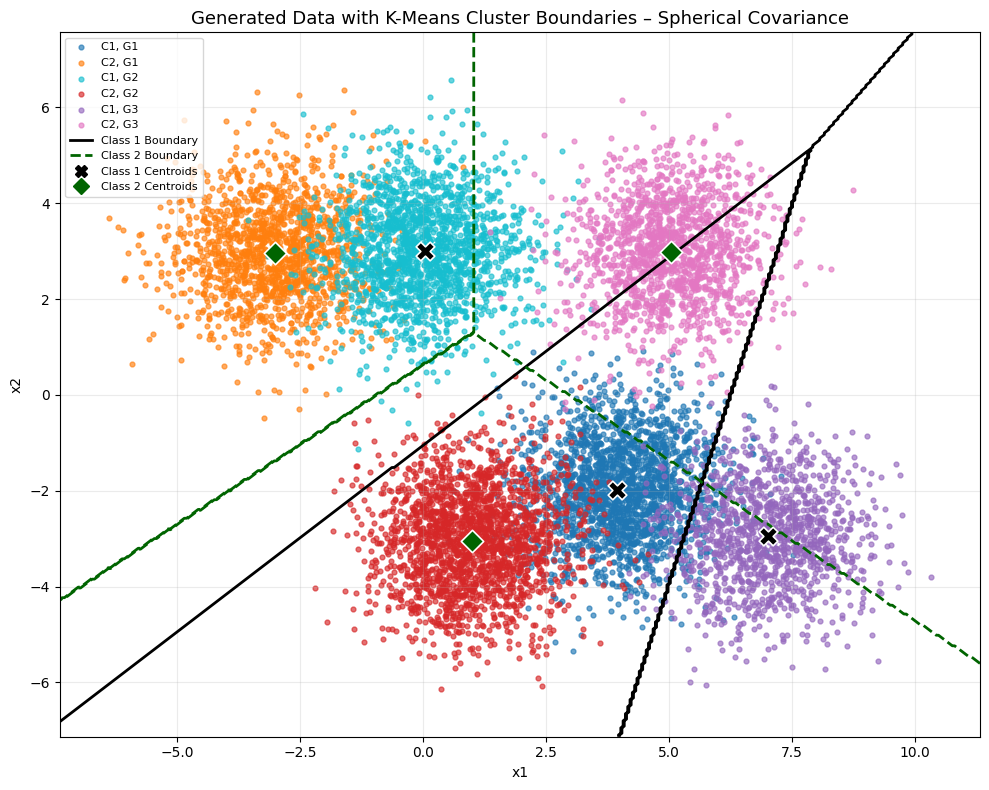

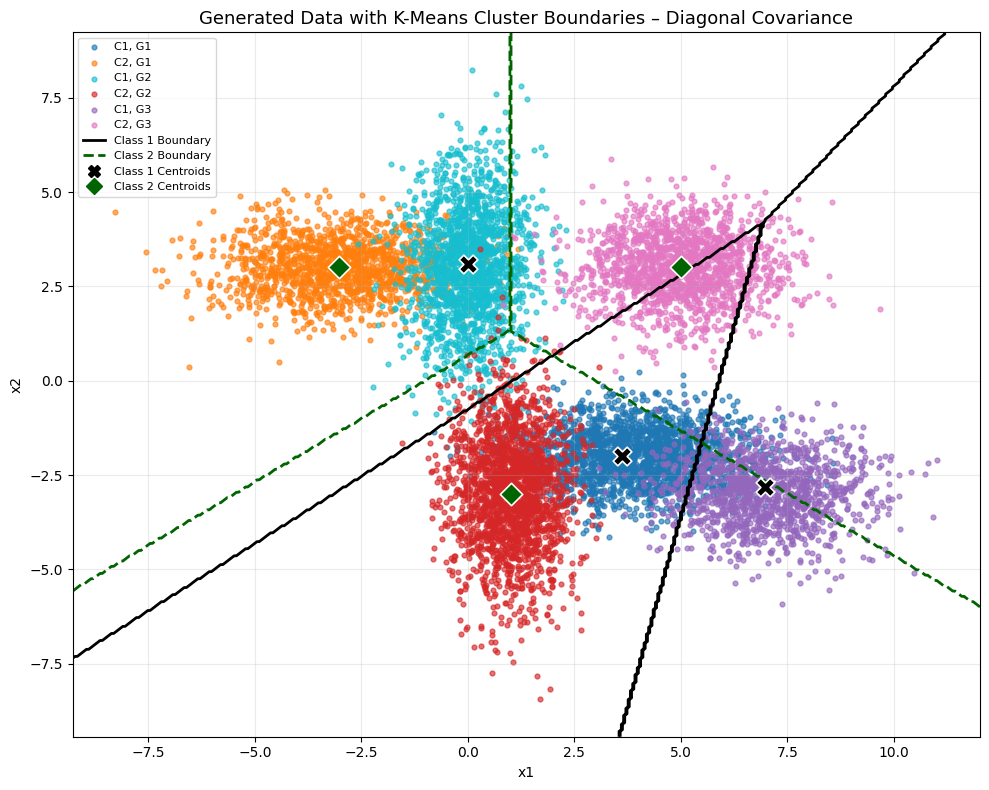

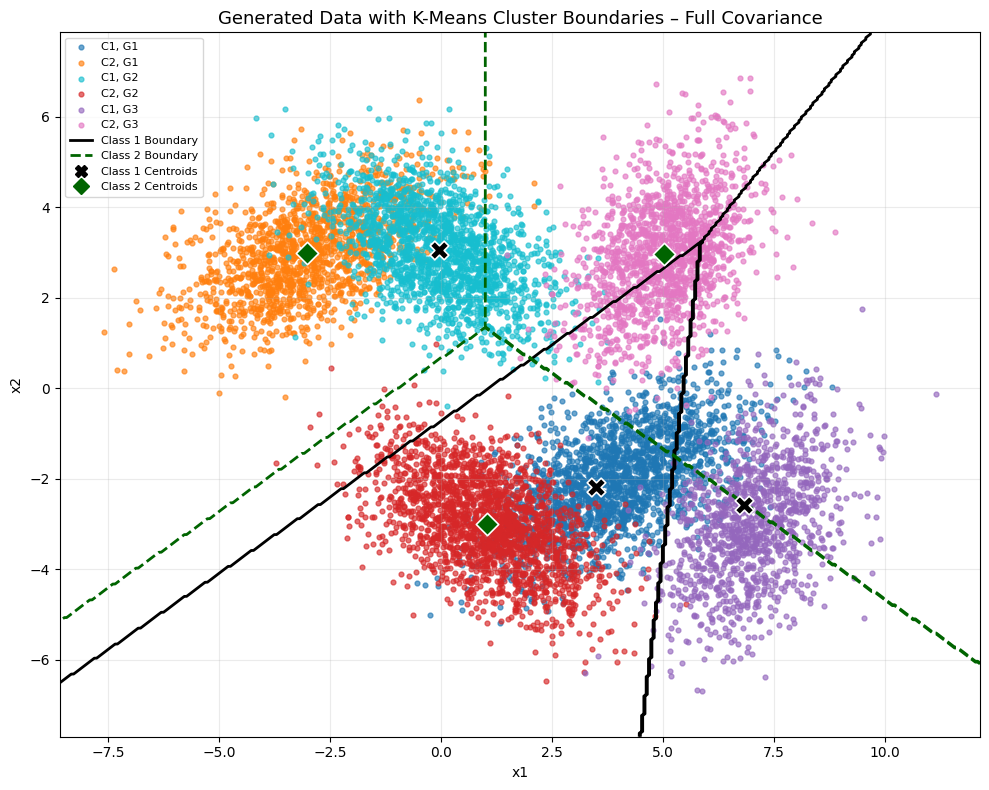

In [11]:
# K-Means Cluster Boundaries
from matplotlib.lines import Line2D
for name in covariance_types:
    fig, ax = plt.subplots(figsize=(10, 8))

    class1 = np.array(generated_data[name]["Class 1"])
    class2 = np.array(generated_data[name]["Class 2"])

    labels1 = np.array(generated_data[name]["Labels 1"])
    labels2 = np.array(generated_data[name]["Labels 2"])

    for comp in range(3):
        mask1 = labels1 == comp
        mask2 = labels2 == comp
        ax.scatter(
            class1[mask1, 0], class1[mask1, 1],
            c=colors[(1, comp)],
            s=12, alpha=0.65,
            label=f"C1, G{comp+1}"
        )
        ax.scatter(
            class2[mask2, 0], class2[mask2, 1],
            c=colors[(2, comp)],
            s=12, alpha=0.65,
            label=f"C2, G{comp+1}"
        )
    # Get K-Means centroids from training data
    c1 = np.array(kmeans_models[name]["Class 1"])
    c2 = np.array(kmeans_models[name]["Class 2"])

    # Create a common grid for both classes
    all_data = np.vstack((class1, class2))
    x_min, x_max = all_data[:, 0].min() - 1, all_data[:, 0].max() + 1
    y_min, y_max = all_data[:, 1].min() - 1, all_data[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    # Find nearest Class 1 centroid for every grid point
    d1 = np.sum((grid[:, None, :] - c1[None, :, :])**2, axis=2)
    Z1 = np.argmin(d1, axis=1).reshape(xx.shape)

    # Find nearest Class 2 centroid for every grid point
    d2 = np.sum((grid[:, None, :] - c2[None, :, :])**2, axis=2)
    Z2 = np.argmin(d2, axis=1).reshape(xx.shape)

    # Class 1 K-Means cluster boundaries
    ax.contour(
        xx, yy, Z1,
        levels=[0.5, 1.5],
        colors="black",
        linewidths=2
    )

    # Class 2 K-Means cluster boundaries
    ax.contour(
        xx, yy, Z2,
        levels=[0.5, 1.5],
        colors="darkgreen",
        linewidths=2,
        linestyles="dashed"
    )

    # Class 1 centroids
    ax.scatter(
        c1[:, 0], c1[:, 1],
        marker="X", s=180,
        c="black", edgecolors="white",
        linewidths=1.2, zorder=5
    )

    # Class 2 centroids
    ax.scatter(
        c2[:, 0], c2[:, 1],
        marker="D", s=130,
        c="darkgreen", edgecolors="white",
        linewidths=1.2, zorder=5
    )

    boundary_legend = [
        Line2D([0], [0], color="black", lw=2,
               label="Class 1 Boundary"),
        Line2D([0], [0], color="darkgreen", lw=2,
               linestyle="--",
               label="Class 2 Boundary"),
        Line2D([0], [0], marker="X", color="black",
               linestyle="None", markersize=9,
               label="Class 1 Centroids"),
        Line2D([0], [0], marker="D", color="darkgreen",
               linestyle="None", markersize=8,
               label="Class 2 Centroids")
    ]
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles + boundary_legend,
        labels + [h.get_label() for h in boundary_legend],
        loc="upper left",
        fontsize=8
    )
    ax.set_title(
        f"Generated Data with K-Means Cluster Boundaries – {name} Covariance",
        fontsize=13
    )
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()